# LQ45 Factor Zoo — Reproducible Research Notebook

**Purpose.** Calculate and explore descriptive cross-sectional Value, Momentum, Quality, and Low Volatility scores. The default uses the same component snapshot as the website; the separate Yahoo Finance ZIP demonstrates rebuilding components from raw prices and fundamentals.

These scores do not predict returns. The default snapshot is historical, and its report date follows the IHSG reference date. The Yahoo sample contains ten issuers and current-snapshot fundamentals, not a historical point-in-time universe. Treat rankings as descriptive research outputs.

## 1. Research question and calculation map

**Question:** given daily issuer closes, daily IHSG closes, and a fundamentals snapshot, what are each issuer’s raw factor inputs and relative cross-sectional scores at the sample cutoff?

The calculation follows the browser implementation: 12–1 return and close/SMA200 for Momentum; inverse positive forward P/E and trailing dividend yield for Value; ROE and direction-reversed debt-to-equity for Quality; and direction-reversed IHSG beta and daily OLS residual volatility for Low Volatility. Each component is winsorized at the eligible cross-sectional 5th/95th percentiles, standardized with the population standard deviation, and clipped to [-3, 3]. Factor scores are the mean of available component z-scores; `AVAILABLE` requires both components, `PARTIAL` means one is available, and `UNAVAILABLE` means neither is available. Missing values are never imputed. Unknown peer groups do not receive Quality scores.

## 2. Imports, runtime checks, and input selection

The default mode reads the same source-derived component CSV as the website and makes **no network request**. Keep a copy of your original files; this notebook reads them but does not rewrite them.

Choose one input mode in the code cell below:

- `website_demo`: default 45-issuer website component snapshot; recalculates scores locally, without raw-price recomputation.
- `bundled_zip`: included ten-issuer Yahoo Finance raw-data example; offline and reproducible.
- `custom_zip`: a ZIP containing `prices.csv`, `ihsg.csv`, and `fundamentals.csv`.
- `custom_csv_dir`: a folder containing those three CSV files.
- `factor_input_csv`: one row per issuer with raw factor-component values; no price-derived feature rebuild.

For raw prices, standard Yahoo Finance columns (`Date, Open, High, Low, Close, Adj Close, Volume`) are accepted; **adjusted close is preferred** when present. Volume and Open/High/Low are not used by the current factors. A benchmark file should contain IHSG/JKSE daily closes. Company-report ratios are needed for Value and Quality.


In [1]:
from __future__ import annotations

import io
import json
import os
import re
import unicodedata
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from IPython.display import display, Image

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

# Choose one input mode. The default is local and offline.
DATA_MODE = os.environ.get("FACTOR_ZOO_DATA_MODE", "website_demo")
CUSTOM_ZIP_PATH = Path(os.environ.get("FACTOR_ZOO_ZIP", "path/to/your/factor-data.zip"))
CUSTOM_CSV_DIR = Path(os.environ.get("FACTOR_ZOO_CSV_DIR", "path/to/your/csv-folder"))
FACTOR_INPUT_PATH = Path(os.environ.get("FACTOR_ZOO_FACTOR_CSV", "path/to/your/factor-inputs.csv"))

# Option A — upload a ZIP in Google Colab (uncomment and choose the file):
# from google.colab import files
# uploaded = files.upload()
# CUSTOM_ZIP_PATH = Path(next(iter(uploaded)))
# DATA_MODE = "custom_zip"

# Option B — read a ZIP from Google Drive in Colab (uncomment and edit the path):
# from google.colab import drive
# drive.mount("/content/drive")
# CUSTOM_ZIP_PATH = Path("/content/drive/MyDrive/quant/factor-data.zip")
# DATA_MODE = "custom_zip"

# Option C — use files attached as a Kaggle dataset (uncomment and edit the path):
# CUSTOM_CSV_DIR = Path("/kaggle/input/my-factor-data")
# DATA_MODE = "custom_csv_dir"

# Option D — read a local ZIP or folder. Edit to the path on your machine:
# macOS / Linux ZIP: CUSTOM_ZIP_PATH = Path("/Users/you/Downloads/factor-data.zip")
# Windows ZIP:       CUSTOM_ZIP_PATH = Path(r"C:\Users\you\Downloads\factor-data.zip")
# Windows CSV dir:   CUSTOM_CSV_DIR = Path(r"C:\Users\you\Downloads\factor-data")
# DATA_MODE = "custom_zip"  # or "custom_csv_dir"

# Option E — score a precomputed raw-component CSV (not precomputed z-scores):
# FACTOR_INPUT_PATH = Path("/path/to/factor-inputs.csv")
# DATA_MODE = "factor_input_csv"

PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "data/examples/yfinance-idx-10y-import.zip").is_file()),
    Path.cwd(),
)
BUNDLED_ZIP = PROJECT_ROOT / "data/examples/yfinance-idx-10y-import.zip"
WEBSITE_DEMO = PROJECT_ROOT / "data/demo-factor-inputs.csv"

print("Python:", os.sys.version.split()[0])
print("pandas:", pd.__version__, "| NumPy:", np.__version__)
print("Plotly:", __import__("plotly").__version__)
print("Selected data mode:", DATA_MODE)
print("Website sample found:", WEBSITE_DEMO.is_file())
print("Yahoo ZIP found:", BUNDLED_ZIP.is_file())


Python: 3.14.2
pandas: 2.2.2 | NumPy: 2.4.1
Plotly: 6.7.0
Selected data mode: website_demo
Website sample found: True
Yahoo ZIP found: True


## 3. Load each source and inspect its provenance

The default component CSV is the same 45-issuer snapshot used by the website. The data are pre-derived components: scores are recalculated here, but historical prices and OLS inputs are not rebuilt from raw series in this mode. The website snapshot references IHSG on 2026-09-24 and reports dated 2026-09-25; it is not a point-in-time backtest.

Select `bundled_zip` for the separate ten-issuer Yahoo Finance sample with adjusted daily prices from 2016-10-31 to 2026-10-30, IHSG, and current-snapshot fundamentals. Custom ZIPs, folders and factor CSVs use the paths configured above. No source is downloaded automatically.

In [2]:
def read_csv_bytes(payload: bytes, name: str) -> pd.DataFrame:
    try:
        return pd.read_csv(io.BytesIO(payload), low_memory=False)
    except Exception as exc:
        raise ValueError(f"Could not read {name} as a CSV: {exc}") from exc


def load_sources(mode: str) -> tuple[dict[str, pd.DataFrame], dict]:
    if mode == "website_demo":
        if not WEBSITE_DEMO.is_file():
            raise FileNotFoundError("Website demo CSV missing; use a full repository checkout or choose a custom input.")
        return {"factor_inputs": pd.read_csv(WEBSITE_DEMO, low_memory=False)}, {
            "source": "IDX Evidence Lab derived component snapshot", "ihsg_reference": "2026-09-24",
            "report_as_of": "2026-09-25", "raw_prices_included": False}
    if mode in {"bundled_zip", "custom_zip"}:
        archive_path = BUNDLED_ZIP if mode == "bundled_zip" else CUSTOM_ZIP_PATH
        if not archive_path.is_file():
            raise FileNotFoundError(f"ZIP not found: {archive_path}. Check DATA_MODE and the path you supplied.")
        with zipfile.ZipFile(archive_path) as archive:
            names = {Path(name).name.lower(): name for name in archive.namelist() if not name.endswith("/")}
            required = ["prices.csv", "ihsg.csv", "fundamentals.csv"]
            missing = [name for name in required if name not in names]
            if missing:
                raise ValueError(f"ZIP is missing required CSV files: {missing}")
            frames = {name[:-4]: read_csv_bytes(archive.read(names[name]), name) for name in required}
            manifest = json.loads(archive.read(names["manifest.json"])) if "manifest.json" in names else {}
            archive_summary = pd.DataFrame([
                {"file": info.filename, "bytes": info.file_size}
                for info in archive.infolist() if not info.is_dir()
            ])
        print("Loaded archive:", archive_path.name)
        display(archive_summary)
        return frames, manifest
    if mode == "custom_csv_dir":
        if not CUSTOM_CSV_DIR.is_dir():
            raise FileNotFoundError(f"CSV directory not found: {CUSTOM_CSV_DIR}")
        required_paths = {name: CUSTOM_CSV_DIR / f"{name}.csv"
                          for name in ("prices", "ihsg", "fundamentals")}
        missing = [str(file_path) for file_path in required_paths.values() if not file_path.is_file()]
        if missing:
            raise FileNotFoundError(f"CSV directory is missing required files: {missing}")
        frames = {name: pd.read_csv(file_path, low_memory=False)
                  for name, file_path in required_paths.items()}
        return frames, {"source": "user-supplied local CSV directory"}
    if mode == "factor_input_csv":
        if not FACTOR_INPUT_PATH.is_file():
            raise FileNotFoundError(f"Factor-input CSV not found: {FACTOR_INPUT_PATH}")
        return {"factor_inputs": pd.read_csv(FACTOR_INPUT_PATH, low_memory=False)}, {
            "source": "user-supplied factor-input CSV"
        }
    raise ValueError("DATA_MODE must be website_demo, bundled_zip, custom_zip, custom_csv_dir, or factor_input_csv.")


sources, source_manifest = load_sources(DATA_MODE)
print("Loaded sources:")
for name, frame in sources.items():
    print(f"  {name}: {frame.shape[0]:,} rows × {frame.shape[1]} columns")
    display(frame.head(3))
if source_manifest:
    print("Provenance fields:", list(source_manifest)[:12])


Loaded sources:
  factor_inputs: 45 rows × 19 columns


,ticker,company,sector,sub_sector,peer_group,report_as_of,price_as_of,price_coverage_start,price_coverage_end,daily_observation_count,aligned_ihsg_returns,earnings_yield,dividend_yield,momentum_12_1,price_vs_ma200,roe,debt_to_equity,beta_ihsg,residual_volatility
0,AADI,PT Adaro Andalan Indonesia Tbk,Energy,"Oil, Gas & Coal",non_financial,2026-09-25,2026-09-24,2024-12-05,2026-09-24,424,414,NaN,0.0478,0.3793,0.2293,0.2083,0.5635,0.5627,0.0310
1,ADMR,PT Alamtri Minerals Indonesia Tbk,Energy,"Oil, Gas & Coal",non_financial,2026-09-25,2026-09-24,2023-09-25,2026-09-24,712,700,0.1129,0.0000,0.6439,-0.0853,0.1579,0.6835,1.0578,0.0311
2,ADRO,Alamtri Resources Indonesia Tbk,Energy,"Oil, Gas & Coal",non_financial,2026-09-25,2026-09-24,2023-09-25,2026-09-24,712,700,0.1986,0.0558,0.4830,0.0989,0.0895,0.3623,0.6843,0.0265


Provenance fields: ['source', 'ihsg_reference', 'report_as_of', 'raw_prices_included']


## 4. Schema, coverage, and data-quality audit

This audit checks required columns, duplicate ticker/date keys, missing close values, invalid non-positive closes, duplicate fundamentals, date coverage, and missing fundamental inputs. These checks do not prove that a provider’s data are correct. For the sample, the manifest identifies adjusted close as the price basis and describes the quote-level fields as a current snapshot.

In [3]:
def normalize_columns(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    normalized = []
    for column in out.columns:
        text = unicodedata.normalize("NFKD", str(column).strip().lower())
        text = "".join(char for char in text if not unicodedata.combining(char))
        text = text.replace("%", " pct ")
        text = re.sub(r"[^a-z0-9]+", "_", text).strip("_")
        normalized.append(text)
    if len(set(normalized)) != len(normalized):
        duplicates = sorted({name for name in normalized if normalized.count(name) > 1})
        raise ValueError(f"Column names collide after normalization: {duplicates}")
    out.columns = normalized
    return out


def rename_first(frame: pd.DataFrame, target: str, aliases: list[str], label: str,
                 required: bool = False) -> pd.DataFrame:
    """Copy the first matching source into the canonical column (including overwrite)."""
    out = frame.copy()
    selected = next((name for name in aliases if name in out.columns), None)
    if selected is None:
        if required:
            raise ValueError(f"{label} is missing a required column. Accepted names: {aliases}")
        return out
    out[target] = out[selected]
    return out


def parse_numeric_value(value, header: str = "") -> float:
    if value is None or pd.isna(value):
        return np.nan
    text = str(value).strip()
    if not text or text.lower() in {"na", "n/a", "nan", "null", "none", "—", "-"}:
        return np.nan
    explicit_percent = text.endswith("%") or re.search(r"(?:^|_)pct(?:_|$)", header or "") is not None
    text = text.replace("%", "").replace(" ", "")
    if "," in text and "." in text:
        text = text.replace(",", "")
    elif "," in text:
        text = text.replace(",", ".")
    try:
        number = float(text)
    except (TypeError, ValueError):
        return np.nan
    if not np.isfinite(number):
        return np.nan
    return number / 100 if explicit_percent else number


def numeric_column(frame: pd.DataFrame, column: str) -> pd.Series:
    return frame[column].map(lambda value: parse_numeric_value(value, column))


def require_columns(frame: pd.DataFrame, required: list[str], label: str) -> None:
    missing = sorted(set(required) - set(frame.columns))
    if missing:
        raise ValueError(f"{label} is missing required columns: {missing}")


if DATA_MODE in {"factor_input_csv", "website_demo"}:
    factor_inputs = normalize_columns(sources["factor_inputs"])
    factor_inputs = rename_first(factor_inputs, "ticker", ["ticker", "symbol", "stock", "code", "kode_saham", "kode_emiten"], "factor-input CSV", required=True)
    prices = ihsg = fundamentals = None
else:
    prices = normalize_columns(sources["prices"])
    ihsg = normalize_columns(sources["ihsg"])
    fundamentals = normalize_columns(sources["fundamentals"])
    prices = rename_first(prices, "date", ["date", "trading_date", "tanggal", "timestamp"], "prices.csv", required=True)
    ihsg = rename_first(ihsg, "date", ["date", "trading_date", "tanggal", "timestamp"], "ihsg.csv", required=True)
    prices = rename_first(prices, "ticker", ["ticker", "symbol", "stock", "code", "kode_saham", "kode_emiten"], "prices.csv", required=True)
    fundamentals = rename_first(fundamentals, "ticker", ["ticker", "symbol", "stock", "code", "kode_saham", "kode_emiten"], "fundamentals.csv", required=True)
    # Prefer Yahoo's adjusted close when a file contains both Close and Adj Close.
    prices = rename_first(prices, "close", ["adj_close", "adjusted_close", "close_adjusted", "close", "close_price", "harga_penutupan"], "prices.csv", required=True)
    ihsg = rename_first(ihsg, "close", ["adj_close", "adjusted_close", "close_adjusted", "close", "close_price", "harga_penutupan"], "ihsg.csv", required=True)
    fundamentals = rename_first(fundamentals, "report_as_of", ["report_as_of", "available_date", "as_of", "date"], "fundamentals.csv")
    fundamentals = rename_first(fundamentals, "company", ["company", "company_name", "issuer"], "fundamentals.csv")
    fundamentals = rename_first(fundamentals, "sector", ["sector", "industry", "sector_name"], "fundamentals.csv")
    fundamentals = rename_first(fundamentals, "sub_sector", ["sub_sector", "subsector", "industry_group"], "fundamentals.csv")
    fundamentals = rename_first(fundamentals, "peer_group", ["peer_group", "peer_group_type"], "fundamentals.csv")
    if "company" not in fundamentals:
        fundamentals["company"] = fundamentals["ticker"]
    if "sector" not in fundamentals:
        fundamentals["sector"] = ""
    if "sub_sector" not in fundamentals:
        fundamentals["sub_sector"] = ""
    if "peer_group" not in fundamentals:
        fundamentals["peer_group"] = ""
    if "report_as_of" not in fundamentals:
        fundamentals["report_as_of"] = pd.NaT
    for frame in (prices, ihsg):
        frame["date"] = pd.to_datetime(frame["date"], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
        frame["close"] = numeric_column(frame, "close")
    prices["ticker"] = prices["ticker"].astype(str).str.upper().str.replace(r"\.JK$", "", regex=True).str.strip()
    fundamentals["ticker"] = fundamentals["ticker"].astype(str).str.upper().str.replace(r"\.JK$", "", regex=True).str.strip()
    if "ticker" in ihsg:
        ihsg["ticker"] = ihsg["ticker"].astype(str).str.upper().str.replace(r"\.JK$", "", regex=True).str.strip()
        symbols = set(ihsg["ticker"].dropna().unique())
        benchmark_symbols = symbols & {"IHSG", "JKSE", "IDX", "IDXCOMPOSITE", "COMPOSITE"}
        if benchmark_symbols:
            ihsg = ihsg.loc[ihsg["ticker"].isin(benchmark_symbols)].copy()
        elif len(symbols) > 1:
            raise ValueError(f"ihsg.csv has multiple unrecognized ticker values: {sorted(symbols)}")
    fundamental_numeric_aliases = {
        "forward_pe": ["forward_pe", "pe_forward", "forward_pe_ratio"],
        "dividend_yield_ttm": ["dividend_yield_ttm", "dividend_yield_ttm_pct", "yield_ttm", "dividend_yield", "dividend_yield_pct", "trailing_dividend_yield"],
        "roe": ["roe", "roe_pct", "return_on_equity", "return_on_equity_pct", "return_on_equity_ratio"],
        "debt_to_equity": ["debt_to_equity", "debt_to_equity_pct", "debt_to_equity_ratio", "der", "der_pct"],
    }
    for target, aliases in fundamental_numeric_aliases.items():
        source = next((name for name in aliases if name in fundamentals.columns), None)
        if source is not None:
            fundamentals[target] = numeric_column(fundamentals, source)
    prices = prices.dropna(subset=["ticker", "date", "close"]).query("close > 0")
    prices = prices.sort_values(["ticker", "date"]).drop_duplicates(["ticker", "date"], keep="last")
    ihsg = ihsg.dropna(subset=["date", "close"]).query("close > 0").sort_values("date").drop_duplicates("date", keep="last")
    fundamentals["report_as_of"] = pd.to_datetime(fundamentals["report_as_of"], errors="coerce", utc=True).dt.tz_localize(None)
    duplicate_fundamental_rows = int(fundamentals.duplicated("ticker", keep=False).sum())
    fundamentals = fundamentals.sort_values("report_as_of", na_position="first").drop_duplicates("ticker", keep="last")

    coverage = prices.groupby("ticker").agg(
        first_date=("date", "min"), last_date=("date", "max"), closes=("close", "size")
    ).reset_index()
    coverage["calendar_years"] = (coverage["last_date"] - coverage["first_date"]).dt.days / 365.25
    print("Issuer price rows:", f"{len(prices):,}", "| Benchmark rows:", f"{len(ihsg):,}")
    print("Duplicate fundamentals before keeping latest row:", duplicate_fundamental_rows)
    display(coverage.sort_values("ticker"))
    print("Potentially missing fundamental fields by column:")
    fundamental_fields = [field for field in ["forward_pe", "dividend_yield_ttm", "roe", "debt_to_equity"] if field in fundamentals]
    display(fundamentals[fundamental_fields].isna().sum().rename("missing_rows").to_frame())


/var/folders/92/6nhl2gvs7t39bfcqvytg33280000gn/T/ipykernel_15508/2331101015.py:26: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  out[target] = out[selected]


## 5. Exploratory view of adjusted close histories

The chart indexes each issuer’s available close history to 100 at its first observed session. When Yahoo-style input contains both `Close` and `Adj Close`, this notebook and the browser importer use `Adj Close` for return features. This is a data inspection view, not a performance comparison: issuer start dates and coverage can differ.

In [4]:
if DATA_MODE not in {"factor_input_csv", "website_demo"}:
    price_plot = prices.copy()
    price_plot["indexed_close"] = price_plot["close"] / price_plot.groupby("ticker")["close"].transform("first") * 100
    fig = px.line(price_plot, x="date", y="indexed_close", color="ticker",
                  title="Sample issuer close histories · rebased to 100",
                  labels={"date": "Date", "indexed_close": "Indexed close", "ticker": "Issuer"})
    fig.update_layout(height=520, hovermode="x unified", legend_title_text="Ticker")
    fig.show()
else:
    print("Price-history chart skipped for factor-input-only mode.")

Price-history chart skipped for factor-input-only mode.


## 6. Feature engineering from prices and fundamentals

**Price features.** With sorted daily closes, the 12–1 return uses `close[t−21] / close[t−252] − 1`; close/SMA200 uses the latest close divided by the mean of the latest 200 closes, minus one. Both require at least 253 closes, matching the browser implementation.

**Market-risk features.** Simple returns are aligned by exact date and by consecutive benchmark observations. OLS is fit as issuer return = alpha + beta × IHSG return + residual. Beta is the slope; residual volatility is the population standard deviation of daily residuals. At least 126 aligned daily returns are required. This residual volatility is daily and is not annualized.

**Fundamentals.** Earnings yield is `1 / forward P/E` only when forward P/E is positive. Dividend yield, ROE, and debt-to-equity are read from the supplied latest row. The sample manifest says these valuation fields are a current quote snapshot; they are not a point-in-time history.

In [5]:
MIN_PRICE_CLOSES = 253
MIN_ALIGNED_RETURNS = 126
MIN_PEERS = 5


def finite_or_nan(value) -> float:
    try:
        number = float(value)
        return number if np.isfinite(number) else np.nan
    except (TypeError, ValueError):
        return np.nan


def classify_peer_group(value) -> str:
    if value is None or pd.isna(value):
        return "unclassified"
    text = str(value).strip().lower()
    text = unicodedata.normalize("NFKD", text)
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = re.sub(r"[^a-z0-9]+", "_", text).strip("_")
    if not text or text in {"na", "n_a", "none", "null", "unknown", "unclassified"}:
        return "unclassified"
    # Check this first: "non-financial" contains the token "financial".
    if "non_financial" in text or "nonfinancial" in text or text in {"non_finance", "nonfinancials"}:
        return "non_financial"
    if any(token in text for token in ("financial", "bank", "insurance", "investment", "securit", "finance")):
        return "financial"
    return "unclassified"


def infer_peer_group(sector) -> str:
    explicit = classify_peer_group(sector)
    if explicit != "unclassified":
        return explicit
    if sector is None or pd.isna(sector):
        return "unclassified"
    text = str(sector).strip()
    missing_labels = {"", "na", "n/a", "nan", "none", "null", "unknown", "unclassified", "—", "-"}
    return "non_financial" if text.lower() not in missing_labels else "unclassified"


def peer_group_for_row(row) -> str:
    supplied = classify_peer_group(row.get("peer_group", ""))
    if supplied != "unclassified":
        return supplied
    return infer_peer_group(row.get("sector", ""))


def issuer_market_risk(issuer_prices: pd.DataFrame, benchmark_prices: pd.DataFrame) -> dict:
    own = issuer_prices.sort_values("date").drop_duplicates("date", keep="last").set_index("date")["close"]
    market = benchmark_prices.sort_values("date").drop_duplicates("date", keep="last").set_index("date")["close"]
    own_frame = pd.DataFrame({"issuer_return": own.pct_change(fill_method=None),
                              "issuer_previous_date": own.index.to_series().shift(1)})
    market_frame = pd.DataFrame({"ihsg_return": market.pct_change(fill_method=None),
                                 "ihsg_position": np.arange(len(market))}, index=market.index)
    market_frame["ihsg_previous_date"] = pd.Series(market.index, index=market.index).shift(1)
    aligned = own_frame.join(market_frame, how="inner").dropna()
    date_gap_days = aligned.index.to_series() - aligned["issuer_previous_date"]
    aligned = aligned.loc[(aligned["issuer_previous_date"] == aligned["ihsg_previous_date"])
                          & date_gap_days.dt.days.le(7)]
    if len(aligned) < MIN_ALIGNED_RETURNS:
        return {"beta_ihsg": np.nan, "idiosyncratic_volatility": np.nan,
                "aligned_ihsg_returns": len(aligned)}
    x = aligned["ihsg_return"].to_numpy(dtype=float)
    y = aligned["issuer_return"].to_numpy(dtype=float)
    centered_x = x - x.mean()
    centered_y = y - y.mean()
    denominator = np.sum(centered_x ** 2)
    if denominator <= 0:
        return {"beta_ihsg": np.nan, "idiosyncratic_volatility": np.nan,
                "aligned_ihsg_returns": len(aligned)}
    beta = np.sum(centered_x * centered_y) / denominator
    alpha = y.mean() - beta * x.mean()
    residual = y - alpha - beta * x
    return {"beta_ihsg": beta, "idiosyncratic_volatility": float(np.std(residual, ddof=0)),
            "aligned_ihsg_returns": len(aligned)}


def build_raw_factor_inputs(price_frame: pd.DataFrame, ihsg_frame: pd.DataFrame,
                            fundamentals_frame: pd.DataFrame) -> pd.DataFrame:
    latest_fundamentals = fundamentals_frame.sort_values("report_as_of", na_position="first")
    latest_fundamentals = latest_fundamentals.drop_duplicates("ticker", keep="last").set_index("ticker")
    rows = []
    benchmark = ihsg_frame[["date", "close"]].dropna().sort_values("date")
    for ticker, issuer_prices in price_frame.groupby("ticker", sort=True):
        history = issuer_prices.sort_values("date").drop_duplicates("date", keep="last")
        closes = history["close"].to_numpy(dtype=float)
        fundamentals = latest_fundamentals.loc[ticker] if ticker in latest_fundamentals.index else pd.Series(dtype=object)
        forward_pe = finite_or_nan(fundamentals.get("forward_pe", fundamentals.get("pe_forward", np.nan)))
        dividend_yield = finite_or_nan(fundamentals.get("dividend_yield_ttm", fundamentals.get("dividend_yield", np.nan)))
        roe = finite_or_nan(fundamentals.get("roe", fundamentals.get("return_on_equity", np.nan)))
        debt_to_equity = finite_or_nan(fundamentals.get("debt_to_equity", fundamentals.get("debt_to_equity_ratio", fundamentals.get("der", np.nan))))
        momentum = closes[-22] / closes[-253] - 1 if len(closes) >= MIN_PRICE_CLOSES else np.nan
        sma200_distance = closes[-1] / np.mean(closes[-200:]) - 1 if len(closes) >= MIN_PRICE_CLOSES else np.nan
        risk = issuer_market_risk(history, benchmark)
        sector = fundamentals.get("sector", "")
        peer_group = peer_group_for_row({"peer_group": fundamentals.get("peer_group", ""), "sector": sector})
        earnings_yield = 1 / forward_pe if np.isfinite(forward_pe) and forward_pe > 0 else np.nan
        if np.isfinite(dividend_yield) and dividend_yield < 0:
            dividend_yield = np.nan
        rows.append({
            "ticker": ticker,
            "company": fundamentals.get("company", ticker),
            "sector": sector,
            "sub_sector": fundamentals.get("sub_sector", ""),
            "peer_group": peer_group,
            "report_as_of": fundamentals.get("report_as_of", pd.NaT),
            "as_of": history["date"].max(),
            "daily_coverage_start": history["date"].min(),
            "daily_coverage_end": history["date"].max(),
            "daily_observation_count": len(history),
            "aligned_ihsg_returns": risk["aligned_ihsg_returns"],
            "forward_pe": forward_pe,
            "earnings_yield": earnings_yield,
            "dividend_yield": dividend_yield,
            "momentum_12_1": momentum,
            "price_vs_ma200": sma200_distance,
            "roe": roe,
            "debt_to_equity": debt_to_equity,
            "beta_ihsg": risk["beta_ihsg"],
            "idiosyncratic_volatility": risk["idiosyncratic_volatility"],
        })
    return pd.DataFrame(rows)


FACTOR_ALIASES = {
    "earnings_yield": ["earnings_yield", "e_yield"],
    "dividend_yield": ["dividend_yield", "dividend_yield_ttm", "yield_ttm", "trailing_dividend_yield"],
    "momentum_12_1": ["momentum_12_1", "12_1_return", "return_12_1"],
    "price_vs_ma200": ["price_vs_ma200", "price_vs_sma200", "close_vs_sma200", "ma200_distance"],
    "roe": ["roe", "return_on_equity", "return_on_equity_ratio"],
    "debt_to_equity": ["debt_to_equity", "debt_to_equity_ratio", "der"],
    "beta_ihsg": ["beta_ihsg", "ihsg_beta", "market_beta"],
    "idiosyncratic_volatility": ["idiosyncratic_volatility", "residual_volatility", "residual_volatility_daily"],
}
component_columns = list(FACTOR_ALIASES)


def first_numeric_alias(frame: pd.DataFrame, names: list[str]) -> pd.Series:
    result = pd.Series(np.nan, index=frame.index, dtype=float)
    for name in names:
        if name in frame.columns:
            values = numeric_column(frame, name)
            result = result.where(result.notna(), values)
    return result


if DATA_MODE in {"factor_input_csv", "website_demo"}:
    raw_factors = factor_inputs.copy()
    raw_factors["ticker"] = raw_factors["ticker"].astype(str).str.upper().str.replace(r"\.JK$", "", regex=True).str.strip()
    raw_factors = raw_factors.loc[raw_factors["ticker"].ne("") & raw_factors["ticker"].str.lower().ne("nan")].copy()
    for name, aliases in FACTOR_ALIASES.items():
        percent_aliases = [f"{alias}_pct" for alias in aliases]
        raw_factors[name] = first_numeric_alias(raw_factors, aliases + percent_aliases)
    # Also accept forward P/E as a raw source for earnings yield when no direct yield was supplied.
    if "forward_pe" in raw_factors:
        forward_pe_values = numeric_column(raw_factors, "forward_pe")
        derived_yield = (1 / forward_pe_values).where(forward_pe_values.gt(0))
        raw_factors["earnings_yield"] = raw_factors["earnings_yield"].where(raw_factors["earnings_yield"].notna(), derived_yield)
    if "company" not in raw_factors:
        raw_factors["company"] = raw_factors["ticker"]
    if "sector" not in raw_factors:
        raw_factors["sector"] = ""
    if "report_as_of" not in raw_factors:
        raw_factors["report_as_of"] = pd.NaT
    if "as_of" not in raw_factors:
        raw_factors["as_of"] = raw_factors["price_as_of"] if "price_as_of" in raw_factors else pd.NaT
    raw_factors["peer_group"] = raw_factors.apply(peer_group_for_row, axis=1)
    # Optional coverage is metadata supplied by the component file, not recomputed.
    for metadata_field in ("daily_observation_count", "aligned_ihsg_returns"):
        if metadata_field in raw_factors:
            raw_factors[metadata_field] = pd.to_numeric(raw_factors[metadata_field], errors="coerce")
        else:
            raw_factors[metadata_field] = np.nan
else:
    raw_factors = build_raw_factor_inputs(prices, ihsg, fundamentals)

raw_factors[component_columns] = raw_factors[component_columns].replace([np.inf, -np.inf], np.nan)
print("Derived issuer count:", len(raw_factors), "| IHSG reference date:",
      (ihsg["date"].max().date().isoformat() if DATA_MODE not in {"factor_input_csv", "website_demo"} else "not recomputed from raw prices"))
display(raw_factors[["ticker", "sector", "peer_group", "daily_observation_count", "aligned_ihsg_returns"] + component_columns].head(12))


Derived issuer count: 45 | IHSG reference date: not recomputed from raw prices


/var/folders/92/6nhl2gvs7t39bfcqvytg33280000gn/T/ipykernel_15508/898454765.py:150: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  raw_factors["ticker"] = raw_factors["ticker"].astype(str).str.upper().str.replace(r"\.JK$", "", regex=True).str.

,ticker,sector,peer_group,daily_observation_count,aligned_ihsg_returns,earnings_yield,dividend_yield,momentum_12_1,price_vs_ma200,roe,debt_to_equity,beta_ihsg,idiosyncratic_volatility
0,AADI,Energy,non_financial,424,414,NaN,0.0478,0.3793,0.2293,0.2083,0.5635,0.5627,0.0310
1,ADMR,Energy,non_financial,712,700,0.1129,0.0000,0.6439,-0.0853,0.1579,0.6835,1.0578,0.0311
2,ADRO,Energy,non_financial,712,700,0.1986,0.0558,0.4830,0.0989,0.0895,0.3623,0.6843,0.0265
3,AKRA,Energy,non_financial,712,700,0.0963,0.0683,0.1098,0.1085,0.1584,1.3422,0.6138,0.0231
4,AMMN,Basic Materials,non_financial,712,700,NaN,NaN,-0.4563,-0.1080,0.0458,1.5539,1.5632,0.0338
5,AMRT,Consumer Non-Cyclicals,non_financial,712,700,0.0916,0.0318,-0.3365,-0.1763,0.1760,1.1967,0.8995,0.0235
6,ANTM,Basic Materials,non_financial,712,700,0.0439,0.0650,-0.0678,-0.0375,0.1970,0.4353,1.0272,0.0268
7,ASII,Industrials,non_financial,712,700,0.1637,0.0832,-0.1309,-0.1740,0.1127,0.7447,0.7386,0.0180
8,BBCA,Financials,financial,712,700,0.0772,0.0610,-0.2062,-0.0875,0.2043,4.6333,0.8696,0.0137
9,BBNI,Financials,financial,712,700,0.1927,0.0000,-0.1579,-0.1053,0.1136,6.7241,1.0564,0.0170


## 7. Cross-sectional scoring and coverage states

For each raw component, eligible values are winsorized using linearly interpolated empirical 5th and 95th percentiles. The winsorized values are converted to population z-scores (ddof = 0), then clipped to [-3, 3]. Debt-to-equity, IHSG beta, and residual volatility are multiplied by −1 so lower inputs receive higher relative scores. ROE and debt-to-equity are standardized separately within financial and non-financial groups. A component needs at least five eligible peers; a factor is `AVAILABLE` only when both of its components are available, `PARTIAL` when exactly one is available, and `UNAVAILABLE` otherwise.

This is a cross-sectional descriptive ranking at the supplied snapshot. It does not test whether a factor predicts future returns.

In [6]:
FACTOR_COMPONENTS = {
    "value": ["earnings_yield", "dividend_yield"],
    "momentum": ["momentum_12_1", "price_vs_ma200"],
    "quality": ["roe", "debt_to_equity"],
    "low_volatility": ["beta_ihsg", "idiosyncratic_volatility"],
}
REVERSED_COMPONENTS = {"debt_to_equity", "beta_ihsg", "idiosyncratic_volatility"}
GROUPED_COMPONENTS = {"roe", "debt_to_equity"}


def score_cross_section(values: pd.Series, reverse: bool) -> tuple[pd.Series, dict]:
    finite = np.isfinite(pd.to_numeric(values, errors="coerce"))
    eligible = pd.to_numeric(values, errors="coerce").loc[finite].astype(float)
    output = pd.Series(np.nan, index=values.index, dtype=float)
    if len(eligible) < MIN_PEERS:
        return output, {"eligible_peers": len(eligible), "status": "INSUFFICIENT_PEERS"}
    lower, upper = np.quantile(eligible.to_numpy(), [0.05, 0.95], method="linear")
    winsorized = eligible.clip(lower=lower, upper=upper)
    mean = float(winsorized.mean())
    population_std = float(winsorized.std(ddof=0))
    if not np.isfinite(population_std) or population_std <= 0:
        return output, {"eligible_peers": len(eligible), "status": "ZERO_CROSS_SECTIONAL_VARIANCE",
                        "winsor_low": lower, "winsor_high": upper}
    z = (winsorized - mean) / population_std
    if reverse:
        z = -z
    output.loc[z.index] = z.clip(-3, 3)
    return output, {"eligible_peers": len(eligible), "status": "AVAILABLE",
                    "winsor_low": float(lower), "winsor_high": float(upper),
                    "winsorized_mean": mean, "population_std": population_std}


scored = raw_factors.copy().reset_index(drop=True)
component_audit = []
for component in component_columns:
    z_column = f"{component}_z"
    status_column = f"{component}_status"
    peers_column = f"{component}_eligible_peers"
    scored[z_column] = np.nan
    scored[status_column] = "UNAVAILABLE"
    scored[peers_column] = 0
    if component in GROUPED_COMPONENTS:
        eligible_groups = ["financial", "non_financial"]
        for group_name in eligible_groups:
            indices = scored.index[scored["peer_group"].eq(group_name)]
            if len(indices) == 0:
                continue
            z, diagnostic = score_cross_section(scored.loc[indices, component], component in REVERSED_COMPONENTS)
            scored.loc[indices, z_column] = z
            scored.loc[indices, peers_column] = diagnostic["eligible_peers"]
            scored.loc[indices, status_column] = diagnostic["status"]
            component_audit.append({"component": component, "peer_group": group_name, **diagnostic})
        unknown = scored["peer_group"].eq("unclassified")
        scored.loc[unknown & scored[component].notna(), status_column] = "UNCLASSIFIED_PEER_GROUP"
        for group_name in sorted(set(scored["peer_group"]) - set(eligible_groups) - {"unclassified"}):
            indices = scored.index[scored["peer_group"].eq(group_name)]
            component_audit.append({"component": component, "peer_group": group_name,
                                    "eligible_peers": 0, "status": "UNCLASSIFIED_PEER_GROUP"})
    else:
        z, diagnostic = score_cross_section(scored[component], component in REVERSED_COMPONENTS)
        scored[z_column] = z
        scored[peers_column] = diagnostic["eligible_peers"]
        scored[status_column] = diagnostic["status"]
        component_audit.append({"component": component, "peer_group": "all peers", **diagnostic})
    scored.loc[scored[component].isna(), status_column] = "UNAVAILABLE"

for factor, components in FACTOR_COMPONENTS.items():
    z_columns = [f"{component}_z" for component in components]
    available_count = scored[z_columns].notna().sum(axis=1)
    scored[f"{factor}_score"] = scored[z_columns].mean(axis=1, skipna=True).clip(-3, 3)
    scored[f"{factor}_status"] = np.select(
        [available_count.eq(len(components)), available_count.gt(0)],
        ["AVAILABLE", "PARTIAL"], default="UNAVAILABLE")
    scored[f"{factor}_components_available"] = available_count

component_audit = pd.DataFrame(component_audit)
coverage = pd.DataFrame({
    factor: scored[f"{factor}_status"].value_counts().reindex(["AVAILABLE", "PARTIAL", "UNAVAILABLE"], fill_value=0)
    for factor in FACTOR_COMPONENTS
}).T
coverage.index.name = "factor"
print("Component scoring diagnostics:")
display(component_audit)
print("Factor coverage by availability state:")
display(coverage)


Component scoring diagnostics:


/var/folders/92/6nhl2gvs7t39bfcqvytg33280000gn/T/ipykernel_15508/947110017.py:61: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  scored[z_column] = z
/var/folders/92/6nhl2gvs7t39bfcqvytg33280000gn/T/ipykernel_15508/947110017.py:61: FutureWarn

,component,peer_group,eligible_peers,status,winsor_low,winsor_high,winsorized_mean,population_std
0,earnings_yield,all peers,36,AVAILABLE,0.0274,0.2132,0.1157,0.0547
1,dividend_yield,all peers,41,AVAILABLE,0.0000,0.1098,0.0371,0.0354
2,momentum_12_1,all peers,45,AVAILABLE,-0.4384,0.6791,0.0202,0.3158
3,price_vs_ma200,all peers,45,AVAILABLE,-0.2761,0.1147,-0.0921,0.1191
4,roe,financial,5,AVAILABLE,0.1001,0.1978,0.1509,0.0375
5,roe,non_financial,40,AVAILABLE,-0.0222,0.3128,0.1159,0.0846
6,debt_to_equity,financial,5,AVAILABLE,4.7971,12.3894,7.4013,2.6825
7,debt_to_equity,non_financial,40,AVAILABLE,0.2023,2.9206,1.0151,0.8022
8,beta_ihsg,all peers,45,AVAILABLE,0.5273,1.9665,1.0009,0.3927
9,idiosyncratic_volatility,all peers,45,AVAILABLE,0.0152,0.0409,0.0271,0.0081


Factor coverage by availability state:


,AVAILABLE,PARTIAL,UNAVAILABLE
factor,,,
value,35,7,3
momentum,45,0,0
quality,45,0,0
low_volatility,45,0,0


## 8. Inspect the computed factor table

The raw inputs remain beside their component z-scores and final factor scores so every chart point can be traced to its ingredients. A displayed score is relative to the eligible peers and the current dataset; importing a different universe or snapshot can change winsorization limits, z-scores, and ranks.

In [7]:
score_columns = [f"{factor}_score" for factor in FACTOR_COMPONENTS]
status_columns = [f"{factor}_status" for factor in FACTOR_COMPONENTS]
component_detail_columns = [column for component in component_columns for column in (
    component, f"{component}_z", f"{component}_status", f"{component}_eligible_peers")]
view_columns = ["ticker", "company", "sector", "peer_group", "as_of", "report_as_of",
                "daily_observation_count", "aligned_ihsg_returns"] + component_detail_columns + score_columns + status_columns
factor_results = scored[[column for column in view_columns if column in scored]].sort_values("ticker")
print("Component columns show raw input, winsorized cross-sectional z-score, availability state, and eligible-peer count.")
display(factor_results.round(5))


Component columns show raw input, winsorized cross-sectional z-score, availability state, and eligible-peer count.


,ticker,company,sector,peer_group,as_of,report_as_of,daily_observation_count,aligned_ihsg_returns,earnings_yield,earnings_yield_z,earnings_yield_status,earnings_yield_eligible_peers,dividend_yield,dividend_yield_z,dividend_yield_status,dividend_yield_eligible_peers,momentum_12_1,momentum_12_1_z,momentum_12_1_status,momentum_12_1_eligible_peers,...,debt_to_equity,debt_to_equity_z,debt_to_equity_status,debt_to_equity_eligible_peers,beta_ihsg,beta_ihsg_z,beta_ihsg_status,beta_ihsg_eligible_peers,idiosyncratic_volatility,idiosyncratic_volatility_z,idiosyncratic_volatility_status,idiosyncratic_volatility_eligible_peers,value_score,momentum_score,quality_score,low_volatility_score,value_status,momentum_status,quality_status,low_volatility_status
0,AADI,PT Adaro Andalan Indonesia Tbk,Energy,non_financial,2026-09-24,2026-09-25,424,414,NaN,NaN,UNAVAILABLE,36,0.0478,0.3039,AVAILABLE,41,0.3793,1.1371,AVAILABLE,45,...,0.5635,0.5629,AVAILABLE,40,0.5626,1.1158,AVAILABLE,45,0.0310,-0.4869,AVAILABLE,45,0.3039,1.4370,0.8270,0.3144,PARTIAL,AVAILABLE,AVAILABLE,AVAILABLE
1,ADMR,PT Alamtri Minerals Indonesia Tbk,Energy,non_financial,2026-09-24,2026-09-25,712,700,0.1129,-0.0523,AVAILABLE,36,0.0000,-1.0487,AVAILABLE,41,0.6439,1.9749,AVAILABLE,45,...,0.6835,0.4134,AVAILABLE,40,1.0578,-0.1449,AVAILABLE,45,0.0311,-0.4931,AVAILABLE,45,-0.5505,1.0159,0.4546,-0.3190,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE
2,ADRO,Alamtri Resources Indonesia Tbk,Energy,non_financial,2026-09-24,2026-09-25,712,700,0.1986,1.5163,AVAILABLE,36,0.0558,0.5299,AVAILABLE,41,0.4829,1.4653,AVAILABLE,45,...,0.3623,0.8138,AVAILABLE,40,0.6843,0.8060,AVAILABLE,45,0.0265,0.0700,AVAILABLE,45,1.0231,1.5346,0.2504,0.4380,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE
3,AKRA,PT AKR Corporindo Tbk.,Energy,non_financial,2026-09-24,2026-09-25,712,700,0.0963,-0.3550,AVAILABLE,36,0.0683,0.8816,AVAILABLE,41,0.1098,0.2836,AVAILABLE,45,...,1.3422,-0.4078,AVAILABLE,40,0.6138,0.9854,AVAILABLE,45,0.0231,0.4841,AVAILABLE,45,0.2633,0.9841,0.0469,0.7348,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE
4,AMMN,PT Amman Mineral Internasional Tbk.,Basic Materials,non_financial,2026-09-24,2026-09-25,712,700,NaN,NaN,UNAVAILABLE,36,NaN,NaN,UNAVAILABLE,41,-0.4563,-1.4519,AVAILABLE,45,...,1.5539,-0.6717,AVAILABLE,40,1.5632,-1.4317,AVAILABLE,45,0.0338,-0.8352,AVAILABLE,45,NaN,-0.7928,-0.7500,-1.1334,UNAVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE
5,AMRT,PT Sumber Alfaria Trijaya Tbk.,Consumer Non-Cyclicals,non_financial,2026-09-24,2026-09-25,712,700,0.0916,-0.4419,AVAILABLE,36,0.0318,-0.1494,AVAILABLE,41,-0.3365,-1.1295,AVAILABLE,45,...,1.1967,-0.2264,AVAILABLE,40,0.8995,0.2580,AVAILABLE,45,0.0235,0.4410,AVAILABLE,45,-0.2957,-0.9185,0.2414,0.3495,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE
6,ANTM,Aneka Tambang Tbk.,Basic Materials,non_financial,2026-09-24,2026-09-25,712,700,0.0439,-1.3146,AVAILABLE,36,0.0650,0.7897,AVAILABLE,41,-0.0678,-0.2787,AVAILABLE,45,...,0.4353,0.7228,AVAILABLE,40,1.0272,-0.0671,AVAILABLE,45,0.0268,0.0300,AVAILABLE,45,-0.2624,0.0901,0.8400,-0.0186,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE
7,ASII,Astra International Tbk,Industrials,non_financial,2026-09-24,2026-09-25,712,700,0.1637,0.8782,AVAILABLE,36,0.0832,1.3028,AVAILABLE,41,-0.1309,-0.4784,AVAILABLE,45,...,0.7447,0.3371,AVAILABLE,40,0.7386,0.6679,AVAILABLE,45,0.0180,1.1148,AVAILABLE,45,1.0905,-0.5832,0.1493,0.8913,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE
8,BBCA,PT Bank Central Asia Tbk.,Financials,financial,2026-09-24,2026-09-25,712,700,0.0772,-0.7049,AVAILABLE,36,0.0610,0.6752,AVAILABLE,41,-0.2062,-0.7169,AVAILABLE,45,...,4.6333,0.9708,AVAILABLE,5,0.8696,0.3342,AVAILABLE,45,0.0138,1.4542,AVAILABLE,45,-0.0149,-0.3393,1.1106,0.8942,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE
9,BBNI,PT Bank Negara Indonesia (Persero) Tbk,Financials,financial,2026-09-24,2026-09-25,712,700,0.1927,1.4089,AVAILABLE,36,0.0000,-1.0487,AVAILABLE,41,-0.1579,-0.5638,AVAILABLE,45,...,6.7241,0.2525,AVAILABLE,5,1.0564,-0.1414,AVAILABLE,45,0.0170,1.2359,AVAILABLE,45,0.1801,-0.3375,-0.3711,0.5472,AVAILABLE

## 9. Choose the three 3D axes

Choose a starting preset or select `custom` and edit `CUSTOM_AXES`. After the 3D chart renders, use its three independent **X**, **Y**, and **Z** dropdowns to explore another combination without rerunning cells. Each dropdown option names its underlying factor components or indicator; the graph axis title keeps the concise concept name. The **color remains Low Volatility**. Individual indicators use their natural cross-sectional z-score, so higher raw beta or DER maps to a higher coordinate; their contributions to Low Volatility and Quality retain the original reversed direction.

Only the indicators assigned to the three selected axes need to be available for an issuer to appear. A missing or partial Low Volatility score is shown in gray. Presets are descriptive combinations, not intrinsic valuation or return predictions.

**Notebook interaction boundary:** the Plotly dropdowns update the chart in the viewer only. They do not change Python variables or the leaderboard below. To update both, edit `AXIS_PRESET`/`CUSTOM_AXES` in the next cell and rerun that cell and all following cells.


In [8]:
# Pick "default", "relative_value", "high_beta_quality", or "custom".
# You may also set FACTOR_ZOO_AXIS_PRESET before launching Jupyter.
AXIS_PRESET = os.environ.get("FACTOR_ZOO_AXIS_PRESET", "default")

# For "custom", select one ID for each axis from AXIS_OPTIONS below.
CUSTOM_AXES = {"x": "factor:value", "y": "factor:momentum", "z": "factor:quality"}
AXIS_OPTIONS = {
    "factor:value": {"label": "Relative Valuation", "column": "value_score", "status": "value_status"},
    "factor:momentum": {"label": "Price Momentum", "column": "momentum_score", "status": "momentum_status"},
    "factor:quality": {"label": "Financial Quality", "column": "quality_score", "status": "quality_status"},
    "earnings_yield": {"label": "Earnings Valuation", "column": "earnings_yield_z", "status": "earnings_yield_status"},
    "dividend_yield": {"label": "Dividend Income", "column": "dividend_yield_z", "status": "dividend_yield_status"},
    "momentum_12_1": {"label": "Long-Term Price Momentum", "column": "momentum_12_1_z", "status": "momentum_12_1_status"},
    "price_vs_ma200": {"label": "Price Trend vs SMA200", "column": "price_vs_ma200_z", "status": "price_vs_ma200_status"},
    "roe": {"label": "Profitability", "column": "roe_z", "status": "roe_status"},
    "debt_to_equity": {"label": "Leverage", "column": "debt_to_equity_z", "status": "debt_to_equity_status"},
    "beta_ihsg": {"label": "Market Sensitivity", "column": "beta_ihsg_z", "status": "beta_ihsg_status"},
    "idiosyncratic_volatility": {"label": "Issuer-Specific Volatility", "column": "idiosyncratic_volatility_z", "status": "idiosyncratic_volatility_status"},
}
# Menus expose the underlying inputs; axis titles remain the concise semantic names.
DROPDOWN_LABELS = {
    "factor:value": "Relative Valuation · earnings/dividends",
    "factor:momentum": "Price Momentum · 12–1 + SMA200",
    "factor:quality": "Financial Quality · ROE/reversed DER",
    "earnings_yield": "Earnings Valuation · earnings yield",
    "dividend_yield": "Dividend Income · dividend yield",
    "momentum_12_1": "Long-Term Price Momentum · 12–1 return",
    "price_vs_ma200": "Price Trend vs SMA200 · MA200 distance",
    "roe": "Profitability · ROE",
    "debt_to_equity": "Leverage · DER",
    "beta_ihsg": "Market Sensitivity · IHSG beta",
    "idiosyncratic_volatility": "Issuer-Specific Volatility · OLS residual",
}
if set(DROPDOWN_LABELS) != set(AXIS_OPTIONS):
    raise ValueError("Every axis option needs a descriptive dropdown label.")
for option_id, detail in DROPDOWN_LABELS.items():
    AXIS_OPTIONS[option_id]["dropdown_label"] = detail

AXIS_PRESETS = {
    "default": {"x": "factor:value", "y": "factor:momentum", "z": "factor:quality"},
    "relative_value": {"x": "earnings_yield", "y": "dividend_yield", "z": "factor:quality"},
    "high_beta_quality": {"x": "beta_ihsg", "y": "factor:quality", "z": "debt_to_equity"},
    "custom": CUSTOM_AXES,
}
if AXIS_PRESET not in AXIS_PRESETS:
    raise ValueError(f"Unknown axis preset {AXIS_PRESET!r}; choose from {list(AXIS_PRESETS)}.")
axis_selection = AXIS_PRESETS[AXIS_PRESET]
if set(axis_selection) != {"x", "y", "z"} or any(value not in AXIS_OPTIONS for value in axis_selection.values()):
    raise ValueError("Select valid X, Y and Z IDs from AXIS_OPTIONS.")
print("Axis preset:", AXIS_PRESET)
display(pd.DataFrame([{"axis": axis.upper(), "indicator": AXIS_OPTIONS[item]["dropdown_label"], "id": item}
                      for axis, item in axis_selection.items()]))
print("Color: Low Volatility score (locked)")

Axis preset: default


,axis,indicator,id
0,X,Relative Valuation · earnings/dividends,factor:value
1,Y,Price Momentum · 12–1 + SMA200,factor:momentum
2,Z,Financial Quality · ROE/reversed DER,factor:quality


Color: Low Volatility score (locked)


## 10. Interactive 3D Factor Zoo

The dropdowns independently replace X, Y, or Z with an existing factor or indicator. Every issuer in the active dataset is retained in the interactive plot; a point is hidden automatically when any selected coordinate is unavailable. Low Volatility controls the color. Hover reveals the ticker, raw inputs, component z-scores, and coverage counts. The generic X/Y/Z values in hover follow the selected axes named above the chart.

The interactive Plotly view needs a compatible notebook renderer. A static image of the **starting selection** is saved below it for GitHub and other viewers; it cannot react to dropdowns. For a self-contained interactive HTML file, set `FACTOR_ZOO_EXPORT_3D_HTML` to a local output path before running; that file may contain the loaded data. Scores are descriptive, not probabilities or expected returns.

/var/folders/92/6nhl2gvs7t39bfcqvytg33280000gn/T/ipykernel_15508/3368307980.py:19: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  plot_source[f"_axis_{axis}"] = axis_coordinates(plot_source, option_id)
/var/folders/92/6nhl2gvs7t39bfcqvytg3328

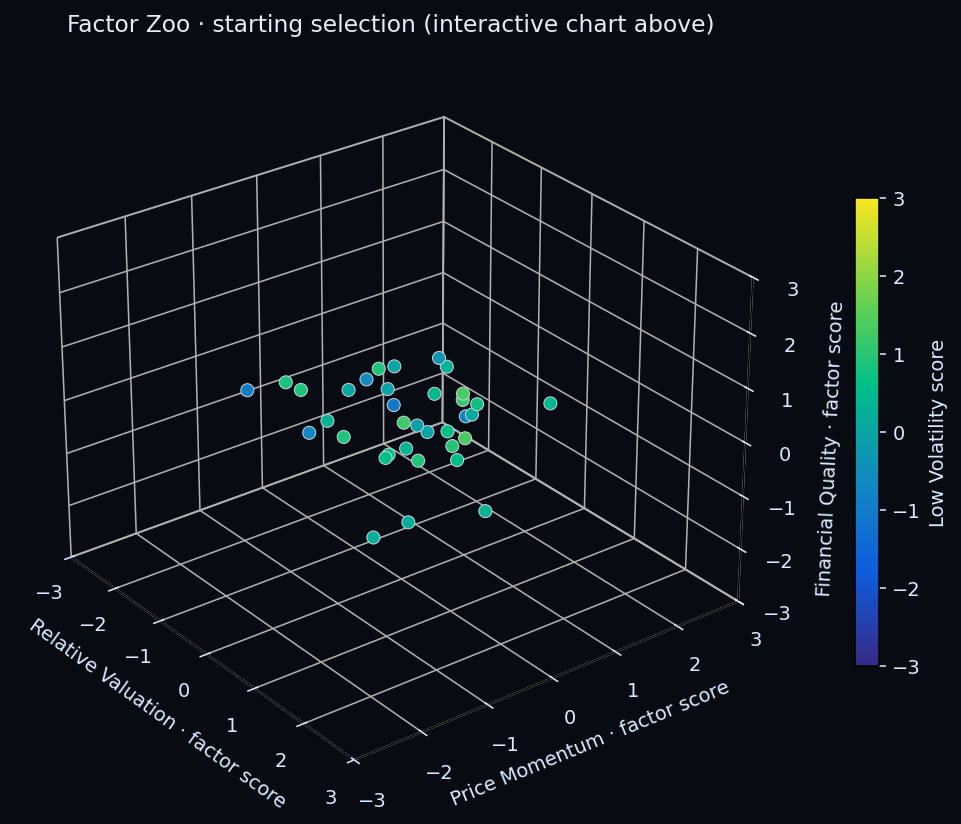

Starting selection · issuers plotted: 35
Starting selection · Low Volatility color available: 35
Starting selection · gray/unavailable Low Volatility markers: 0
Dropdowns recalculate visible points from all issuers; these counts and the static preview reflect the starting selection only.


In [9]:
def axis_coordinates(frame: pd.DataFrame, option_id: str) -> list:
    """Return one coordinate per issuer; unavailable values become JSON null."""
    option = AXIS_OPTIONS[option_id]
    direction = -1 if option_id in REVERSED_COMPONENTS else 1
    values = pd.to_numeric(frame[option["column"]], errors="coerce") * direction
    valid = frame[option["status"]].eq("AVAILABLE") & np.isfinite(values)
    return [float(value) if is_valid else None for value, is_valid in zip(values, valid)]


def axis_title(option_id: str) -> str:
    units = "factor score" if option_id.startswith("factor:") else "natural component z"
    return f"{AXIS_OPTIONS[option_id]['label']} · {units}"


# Keep every issuer in the interactive traces. Null coordinates hide only the
# issuers that are missing one of the axes currently selected by the user.
plot_source = scored.copy()
for axis, option_id in axis_selection.items():
    plot_source[f"_axis_{axis}"] = axis_coordinates(plot_source, option_id)
    plot_source[f"_axis_{axis}_status"] = plot_source[AXIS_OPTIONS[option_id]["status"]]
axis_status_columns = [f"_axis_{axis}_status" for axis in ("x", "y", "z")]
initial_visible = (plot_source[axis_status_columns].eq("AVAILABLE").all(axis=1)
                   & plot_source[["_axis_x", "_axis_y", "_axis_z"]].notna().all(axis=1))
plot_data = plot_source.loc[initial_visible].copy()
plot_data["low_volatility_display"] = plot_data["low_volatility_score"].where(
    plot_data["low_volatility_status"].eq("AVAILABLE"), np.nan)

component_z_columns = [f"{name}_z" for name in component_columns]
component_status_columns = [f"{name}_status" for name in component_columns]
component_peer_columns = [f"{name}_eligible_peers" for name in component_columns]
plot_source["low_volatility_label"] = np.where(
    plot_source["low_volatility_status"].eq("AVAILABLE"),
    plot_source["low_volatility_score"].map(lambda value: f"{value:+.2f}"),
    "unavailable",
)
custom_columns = (["company", "sector", "peer_group", "as_of", "report_as_of"]
                  + component_columns + component_z_columns + component_status_columns
                  + component_peer_columns + ["low_volatility_label"])
colorscale = [[0.00, "#352a87"], [0.20, "#0f5cdd"], [0.40, "#128ac0"],
              [0.60, "#00bf87"], [0.80, "#76d34b"], [1.00, "#f9e721"]]
# Coordinate labels must stay generic: the axis titles change with dropdowns.
hovertemplate = (
    "<b>%{text} · %{customdata[0]}</b><br>%{customdata[1]} · %{customdata[2]} peers"
    "<br>Issuer prices through %{customdata[3]} · report as of %{customdata[4]}"
    "<br><br><b>Selected coordinates</b>"
    "<br>X: %{x:+.2f} · Y: %{y:+.2f} · Z: %{z:+.2f}"
    "<br><br><b>Value inputs</b>"
    "<br>Earnings yield %{customdata[5]:.2%} · z %{customdata[13]:+.2f} · %{customdata[21]} · n=%{customdata[29]}"
    "<br>Dividend yield %{customdata[6]:.2%} · z %{customdata[14]:+.2f} · %{customdata[22]} · n=%{customdata[30]}"
    "<br><br><b>Momentum inputs</b>"
    "<br>12–1 return %{customdata[7]:.2%} · z %{customdata[15]:+.2f} · %{customdata[23]} · n=%{customdata[31]}"
    "<br>Close/SMA200 − 1 %{customdata[8]:.2%} · z %{customdata[16]:+.2f} · %{customdata[24]} · n=%{customdata[32]}"
    "<br><br><b>Quality inputs</b>"
    "<br>ROE %{customdata[9]:.2%} · z %{customdata[17]:+.2f} · %{customdata[25]} · n=%{customdata[33]}"
    "<br>Debt/equity %{customdata[10]:.3f} · reversed z %{customdata[18]:+.2f} · %{customdata[26]} · n=%{customdata[34]}"
    "<br><br><b>Low Volatility color</b>: %{customdata[11]:.3f} beta; residual volatility %{customdata[12]:.2%}; score %{customdata[37]}σ (%{customdata[28]})"
    "<extra></extra>"
)
lowvol_complete = (plot_source["low_volatility_status"].eq("AVAILABLE")
                   & np.isfinite(pd.to_numeric(plot_source["low_volatility_score"], errors="coerce")))
trace_frames = [plot_source.loc[lowvol_complete].copy(), plot_source.loc[~lowvol_complete].copy()]
fig = go.Figure()
for frame, color_available in zip(trace_frames, (True, False)):
    marker = {"size": 6, "line": {"width": 0.7, "color": "#dbeafe"}}
    if color_available:
        marker.update({"color": frame["low_volatility_score"].tolist(), "colorscale": colorscale,
                       "cmin": -3, "cmax": 3, "colorbar": {"title": "Low Volatility"}})
    else:
        marker["color"] = "#778493"
    fig.add_trace(go.Scatter3d(
        x=axis_coordinates(frame, axis_selection["x"]),
        y=axis_coordinates(frame, axis_selection["y"]),
        z=axis_coordinates(frame, axis_selection["z"]),
        mode="markers", text=frame["ticker"].tolist(), marker=marker,
        customdata=frame[custom_columns].to_numpy(dtype=object), hovertemplate=hovertemplate,
        name="Complete Low Volatility score" if color_available else "Low Volatility unavailable or partial"))

option_ids = list(AXIS_OPTIONS)
menus = []
for position, axis in enumerate(("x", "y", "z")):
    buttons = []
    for option_id in option_ids:
        buttons.append({
            "label": AXIS_OPTIONS[option_id]["dropdown_label"], "method": "update",
            "args": [{axis: [axis_coordinates(frame, option_id) for frame in trace_frames]},
                     {f"scene.{axis}axis.title.text": axis_title(option_id)}],
        })
    menus.append({"buttons": buttons, "active": option_ids.index(axis_selection[axis]),
                  "direction": "down", "showactive": True, "x": position / 3, "xanchor": "left",
                  "y": 1.12, "yanchor": "top", "pad": {"r": 8, "t": 12}})
annotations = [{"text": f"{axis.upper()} axis", "x": position / 3, "y": 1.16,
                "xref": "paper", "yref": "paper", "showarrow": False, "xanchor": "left"}
               for position, axis in enumerate(("x", "y", "z"))]
fig.update_layout(template="plotly_dark",
                  scene={"xaxis_title": axis_title(axis_selection["x"]),
                         "yaxis_title": axis_title(axis_selection["y"]),
                         "zaxis_title": axis_title(axis_selection["z"]),
                         "xaxis": {"range": [-3, 3]}, "yaxis": {"range": [-3, 3]},
                         "zaxis": {"range": [-3, 3]}, "aspectmode": "cube"},
                  updatemenus=menus, annotations=annotations,
                  height=820, margin={"l": 0, "r": 0, "t": 130, "b": 0})
factor_zoo_figure = fig  # Preserve the 3D figure when later cells create other charts.
fig.show()
export_path = os.environ.get("FACTOR_ZOO_EXPORT_3D_HTML", "").strip()
if export_path:
    fig.write_html(export_path, include_plotlyjs=True, full_html=True)
    print("Interactive HTML exported:", Path(export_path).name)

# Static fallback represents the starting selection; dropdown changes are interactive only.
if plot_data.empty:
    print("No issuer has all three starting axes available; use the dropdowns to explore other combinations.")
else:
    cmap = LinearSegmentedColormap.from_list("factor_zoo", [color for _, color in colorscale])
    norm = Normalize(vmin=-3, vmax=3)
    static_fig = plt.figure(figsize=(10, 7), facecolor="#080b12")
    ax = static_fig.add_subplot(111, projection="3d", facecolor="#080b12")
    ax.tick_params(colors="#dbeafe")
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.label.set_color("#dbeafe")
        axis.pane.fill = False
    static_lowvol = plot_data["low_volatility_status"].eq("AVAILABLE") & plot_data["low_volatility_score"].notna()
    for frame, available in ((plot_data.loc[static_lowvol], True), (plot_data.loc[~static_lowvol], False)):
        if frame.empty:
            continue
        colors = cmap(norm(frame["low_volatility_score"].to_numpy(dtype=float))) if available else "#778493"
        ax.scatter(frame["_axis_x"], frame["_axis_y"], frame["_axis_z"],
                   c=colors, s=45, edgecolors="#cbd5e1", linewidths=0.5, depthshade=False)
    ax.set(xlim=(-3, 3), ylim=(-3, 3), zlim=(-3, 3),
           xlabel=axis_title(axis_selection["x"]), ylabel=axis_title(axis_selection["y"]),
           zlabel=axis_title(axis_selection["z"]))
    ax.view_init(elev=28, azim=-37.5)
    ax.set_title("Factor Zoo · starting selection (interactive chart above)", color="#e6edf7", pad=12)
    colorbar = static_fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=.62, pad=.08)
    colorbar.set_label("Low Volatility score", color="#dbeafe")
    colorbar.ax.yaxis.set_tick_params(color="#dbeafe", labelcolor="#dbeafe")
    image_buffer = io.BytesIO()
    static_fig.savefig(image_buffer, format="png", dpi=140, bbox_inches="tight", facecolor=static_fig.get_facecolor())
    display(Image(data=image_buffer.getvalue()))
    plt.close(static_fig)
print("Starting selection · issuers plotted:", len(plot_data))
print("Starting selection · Low Volatility color available:", int(plot_data["low_volatility_status"].eq("AVAILABLE").sum()))
print("Starting selection · gray/unavailable Low Volatility markers:", int((~plot_data["low_volatility_status"].eq("AVAILABLE")).sum()))
print("Dropdowns recalculate visible points from all issuers; these counts and the static preview reflect the starting selection only.")

## 11. Rank the selected axes and Low Volatility

These tables rank only issuers plotted on **all three starting axes** above, matching the website. A Low Volatility color row also requires an available color score. Choose Top 5, 10, 15, or all plotted names in the next cell. Ranking direction is determined automatically by the selected indicator: **lower** for debt-to-equity and residual volatility, **higher** for the other selected indicators and existing composites; Low Volatility color remains higher. High beta is a choice of exposure, not a claim of lower risk or better returns. Debt-to-equity requires particular care with banks and negative equity.

The ranking score is the displayed axis score when higher is preferred and its negative when lower is preferred. Tables show both the **original axis score** and **ranking score**; the 3D coordinates and raw values are unchanged. Scores describe this sample, not predicted performance or recommendations. The tables follow the Python `axis_selection`; browser-only Plotly dropdown changes do not update these Python results. After changing `AXIS_PRESET` or `CUSTOM_AXES`, rerun from the axis selection cell onward.


X · Relative Valuation · higher is the ranking criterion · showing 5 of 35 eligible plotted issuers


/var/folders/92/6nhl2gvs7t39bfcqvytg33280000gn/T/ipykernel_15508/3995735516.py:20: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  eligible["ranking_score"] = eligible["axis_score"] * (-1 if spec["direction"] == "lower" else 1)


,ticker,axis_score,ranking_score
0,BMRI,+1.458,+1.458
1,UNTR,+1.264,+1.264
2,BBRI,+1.248,+1.248
3,ASII,+1.090,+1.090
4,ADRO,+1.023,+1.023


Y · Price Momentum · higher is the ranking criterion · showing 5 of 35 eligible plotted issuers


/var/folders/92/6nhl2gvs7t39bfcqvytg33280000gn/T/ipykernel_15508/3995735516.py:20: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  eligible["ranking_score"] = eligible["axis_score"] * (-1 if spec["direction"] == "lower" else 1)


,ticker,axis_score,ranking_score
0,ADRO,+1.535,+1.535
1,INDY,+1.386,+1.386
2,ISAT,+1.225,+1.225
3,MAPI,+1.222,+1.222
4,ADMR,+1.016,+1.016


... (2 outputs left out)

,ticker,axis_score,ranking_score
0,BBCA,+1.111,+1.111
1,NCKL,+0.879,+0.879
2,ANTM,+0.840,+0.840
3,CPIN,+0.710,+0.710
4,KLBF,+0.673,+0.673


Color · Low Volatility · higher is the ranking criterion · showing 5 of 35 eligible plotted issuers


/var/folders/92/6nhl2gvs7t39bfcqvytg33280000gn/T/ipykernel_15508/3995735516.py:20: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  eligible["ranking_score"] = eligible["axis_score"] * (-1 if spec["direction"] == "lower" else 1)


,ticker,axis_score,ranking_score
0,INDF,+1.330,+1.330
1,ITMG,+1.330,+1.330
2,ICBP,+1.203,+1.203
3,PTBA,+1.141,+1.141
4,UNTR,+0.962,+0.962


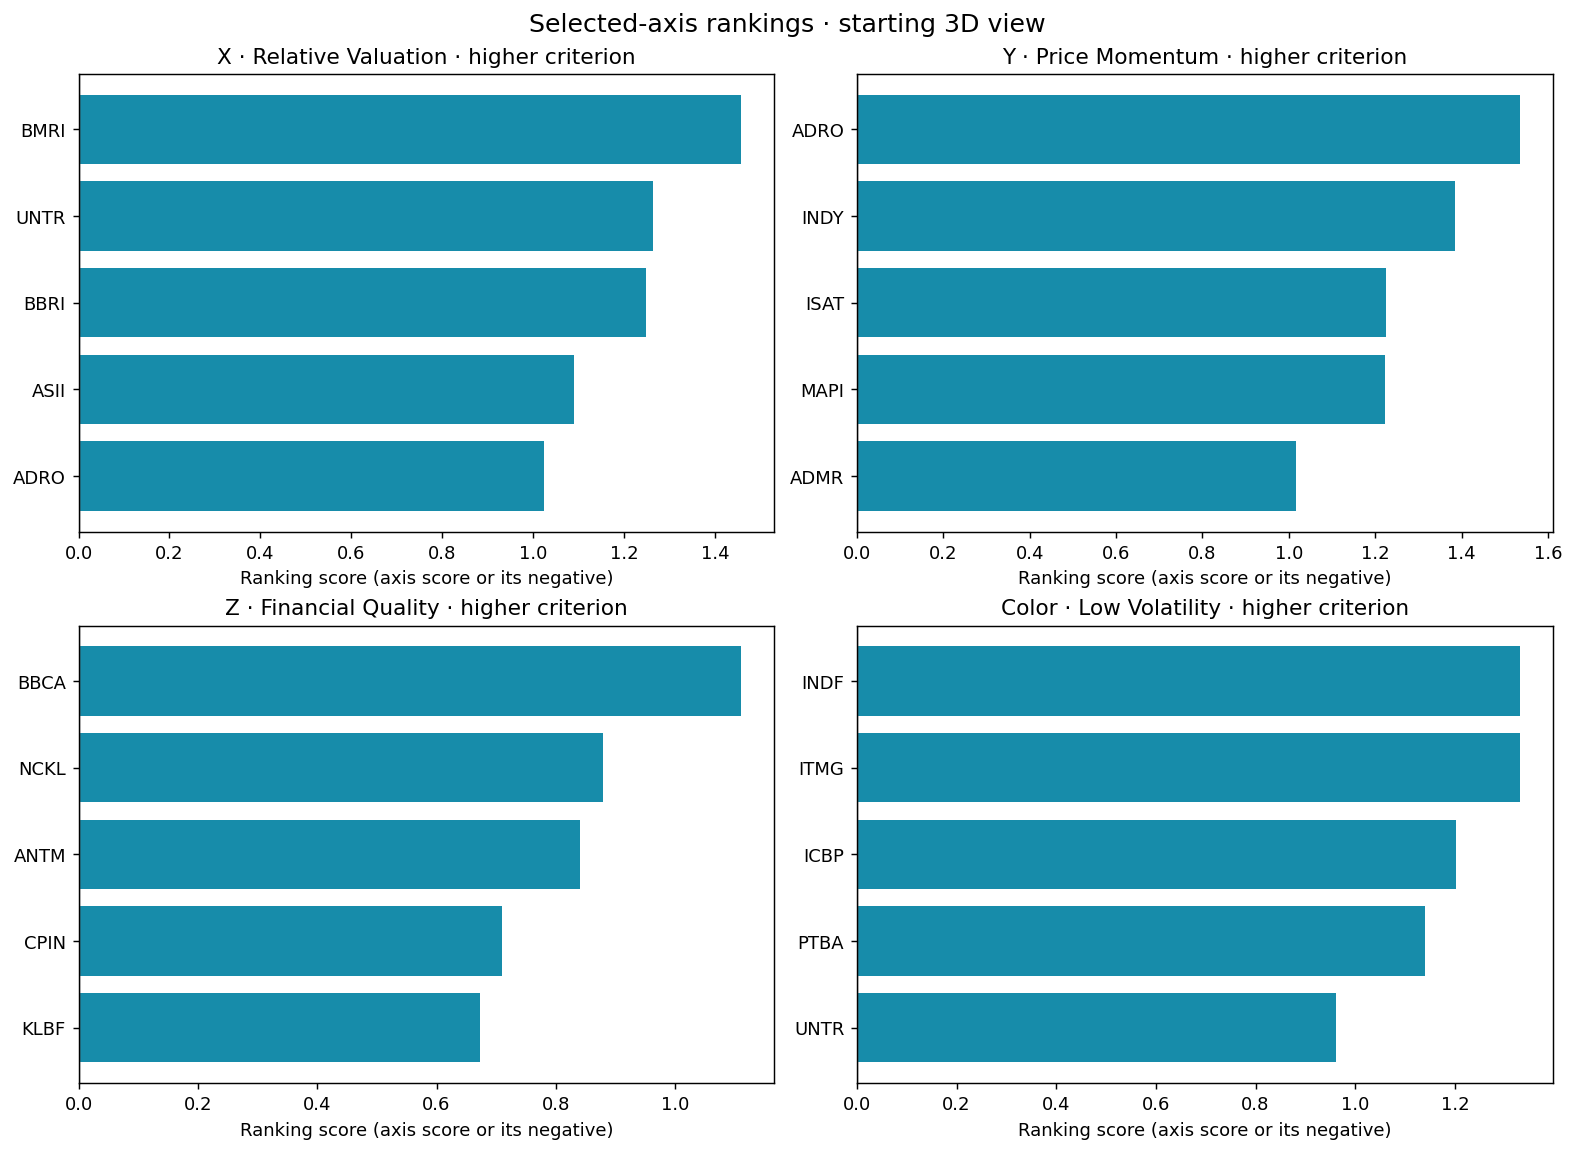

In [10]:
# Set 5, 10, 15, or "all". This is independent of the Plotly dropdowns.
LEADERBOARD_LIMIT = os.environ.get("FACTOR_ZOO_LEADERBOARD_LIMIT", "5").strip().lower()
if LEADERBOARD_LIMIT not in {"5", "10", "15", "all"}:
    raise ValueError("LEADERBOARD_LIMIT must be 5, 10, 15, or 'all'.")

# Ranking direction follows the indicator; it is not a user-selected switch.
lower_preferred = {"debt_to_equity", "idiosyncratic_volatility"}
rank_directions = {
    axis: "lower" if option_id in lower_preferred else "higher"
    for axis, option_id in axis_selection.items()
}
rank_specs = {axis: {"label": f"{axis.upper()} · {AXIS_OPTIONS[option_id]['label']}",
                     "direction": rank_directions[axis], "column": f"_axis_{axis}"}
              for axis, option_id in axis_selection.items()}
rank_specs["low"] = {"label": "Color · Low Volatility", "direction": "higher", "column": "low_volatility_display"}
leaderboard_frames = {}
for key, spec in rank_specs.items():
    eligible = plot_data.loc[plot_data[spec["column"]].notna(), ["ticker", spec["column"]]].copy()
    eligible = eligible.rename(columns={spec["column"]: "axis_score"})
    eligible["ranking_score"] = eligible["axis_score"] * (-1 if spec["direction"] == "lower" else 1)
    eligible = eligible.sort_values(["ranking_score", "ticker"], ascending=[False, True])
    board = eligible if LEADERBOARD_LIMIT == "all" else eligible.head(int(LEADERBOARD_LIMIT))
    leaderboard_frames[key] = board.reset_index(drop=True)
    print(f"{spec['label']} · {spec['direction']} is the ranking criterion · showing {len(board)} of {len(eligible)} eligible plotted issuers")
    display(leaderboard_frames[key].style.format({"axis_score": "{:+.3f}", "ranking_score": "{:+.3f}"}))

# Visualize ranking scores; original axis scores remain visible in the tables above.
boards_fig, axes = plt.subplots(2, 2, figsize=(12, max(7, min(20, len(plot_data) * .25))), constrained_layout=True)
for ax, (key, board) in zip(axes.flat, leaderboard_frames.items()):
    spec = rank_specs[key]
    ax.set_title(f"{spec['label']} · {spec['direction']} criterion")
    if board.empty:
        ax.text(.5, .5, "No eligible plotted issuers", ha="center", va="center", transform=ax.transAxes)
    else:
        ordered = board.iloc[::-1]
        ax.barh(ordered["ticker"], ordered["ranking_score"], color="#178caa")
        ax.axvline(0, color="#666", linewidth=.8)
    ax.set_xlabel("Ranking score (axis score or its negative)")
boards_fig.suptitle("Selected-axis rankings · starting 3D view", fontsize=14)
board_buffer = io.BytesIO()
boards_fig.savefig(board_buffer, format="png", dpi=130, bbox_inches="tight")
display(Image(data=board_buffer.getvalue()))
plt.close(boards_fig)


## 12. Descriptive diagnostics, not strategy performance

A score correlation matrix can reveal that these factor dimensions overlap in this particular sample. It does not establish causality or future returns. This notebook does **not** report strategy performance, Sharpe ratio, CAGR, hit rate, or predictive accuracy because it does not construct a historical point-in-time investable universe or execute a chronological portfolio backtest.

**Which evaluation metric applies?** MAE requires a numeric prediction and a realized target; accuracy, precision and recall require a defined class and corresponding labels. This descriptive snapshot has neither future predictions nor labels, so reporting those values here would be misleading. A future historical study may evaluate factor ranks against subsequent returns (for example rank IC), or define an explicit prediction/classification task with chronological holdout and appropriate baselines. Coverage and missingness are measurable now and are reported above.

In [11]:
score_matrix = scored[[f"{factor}_score" for factor in FACTOR_COMPONENTS]].rename(
    columns={f"{factor}_score": factor.replace("_", " ").title() for factor in FACTOR_COMPONENTS}
)
if len(score_matrix.dropna(how="all")) >= 2:
    correlation = score_matrix.corr(min_periods=2)
    fig = px.imshow(correlation, text_auto=".2f", color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                    title="Descriptive factor-score correlation · current sample")
    fig.update_layout(height=480)
    fig.show()
    display(correlation)
else:
    print("Too few complete factor observations for a descriptive correlation matrix.")

,Value,Momentum,Quality,Low Volatility
Value,1.0000,0.1252,0.0448,0.6606
Momentum,0.1252,1.0000,-0.0027,0.1203
Quality,0.0448,-0.0027,1.0000,0.2029
Low Volatility,0.6606,0.1203,0.2029,1.0000


## 13. Checks, interpretation, and research limitations

The final cell checks ticker uniqueness, score bounds, selected-axis rankings and directions, plot eligibility, non-financial peer classification, literal and header-marked percentage parsing, and that unclassified issuers receive no Quality score. The default is the website component snapshot and makes no network calls; `bundled_zip` selects the separate ten-issuer yfinance example. It is not the full IDX universe or historical LQ45 membership. Its current company-report snapshot is not point-in-time historical data.

This notebook calculates and visualizes descriptive factors. It does **not** estimate predictive performance, returns, strategy profitability, or investment recommendations. A defensible historical factor study needs historical constituents and delistings, point-in-time fundamentals, predeclared rebalancing, execution costs, and chronological out-of-sample validation.

In [12]:
assert len(scored) > 0, "No issuer records were produced."
assert scored["ticker"].notna().all(), "Some output rows have no ticker."
assert scored["ticker"].is_unique, "Factor output contains duplicate ticker rows."
for factor in FACTOR_COMPONENTS:
    values = scored[f"{factor}_score"].dropna()
    assert values.between(-3, 3).all(), f"{factor} score exceeds the documented clipping range."
    assert scored.loc[scored[f"{factor}_status"].eq("AVAILABLE"), f"{factor}_components_available"].eq(2).all()
for key, board in leaderboard_frames.items():
    spec = rank_specs[key]
    assert set(board["ticker"]).issubset(set(plot_data["ticker"])), f"{key} ranking includes an unplotted issuer."
    if key == "low":
        available = set(plot_data.loc[plot_data["low_volatility_status"].eq("AVAILABLE"), "ticker"])
        assert set(board["ticker"]).issubset(available), "Color ranking includes an unavailable score."
    if not board.empty:
        expected = board["axis_score"] * (-1 if spec["direction"] == "lower" else 1)
        assert np.allclose(board["ranking_score"], expected), f"{key} ranking direction is wrong."
        assert board["ranking_score"].is_monotonic_decreasing, f"{key} ranking order is wrong."
assert plot_data[axis_status_columns].eq("AVAILABLE").all().all(), "3D plot includes an incomplete selected axis."
assert plot_data.loc[plot_data["low_volatility_status"].ne("AVAILABLE"), "low_volatility_display"].isna().all(), "Missing Low Volatility scores must not be drawn as zero."
assert classify_peer_group("Non-financial peers") == "non_financial", "Non-financial peer labels were misclassified."
assert classify_peer_group("Financial Services") == "financial", "Financial peer labels were misclassified."
assert infer_peer_group("") == "unclassified", "Missing sector data must remain unclassified."
assert classify_peer_group(np.nan) == "unclassified", "NaN peer labels must remain unclassified."
assert infer_peer_group(np.nan) == "unclassified", "NaN sectors must not be inferred as non-financial."
close_probe = rename_first(pd.DataFrame({"close": [100.0], "adj_close": [90.0]}),
                           "close", ["adj_close", "adjusted_close", "close"], "probe", required=True)
assert close_probe.loc[0, "close"] == 90.0, "Adjusted close must take precedence when both close columns exist."
assert np.isclose(parse_numeric_value("16%", "roe"), 0.16), "Literal percent values must convert to decimals."
assert np.isclose(parse_numeric_value("16", "roe_pct"), 0.16), "_pct fields must convert to decimals."
assert np.isclose(parse_numeric_value("0,16", "roe"), 0.16), "Decimal-comma values must parse correctly."
unknown_quality = scored.loc[scored["peer_group"].eq("unclassified"), ["roe_z", "debt_to_equity_z"]]
assert unknown_quality.isna().all().all(), "Unclassified issuers must not receive Quality z-scores."

if DATA_MODE == "website_demo":
    assert scored["ticker"].nunique() == 45, "Website demo issuer count changed; review the snapshot."
    if axis_selection == AXIS_PRESETS["default"]:
        assert len(plot_data) == 35, "Website demo plotted count changed; review scoring and input coverage."

if DATA_MODE == "bundled_zip":
    assert scored["ticker"].nunique() == 10, "The bundled sample's issuer count changed; review the data manifest."
    assert scored["daily_observation_count"].min() >= 2000, "Expected long daily histories in the bundled sample."
    assert scored["aligned_ihsg_returns"].min() >= MIN_ALIGNED_RETURNS, "Risk feature coverage is below the configured minimum."

def optional_integer_min(series: pd.Series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    return int(values.min()) if not values.empty else None


run_summary = pd.DataFrame([{
    "data_mode": DATA_MODE,
    "issuer_count": scored["ticker"].nunique(),
    "sample_as_of": str(scored["as_of"].max())[:10] if "as_of" in scored and scored["as_of"].notna().any() else "not supplied",
    "plotted_issuers": len(plot_data),
    "low_volatility_color_available": int(plot_data["low_volatility_status"].eq("AVAILABLE").sum()),
    "minimum_issuer_closes": optional_integer_min(scored["daily_observation_count"]) if "daily_observation_count" in scored else None,
    "minimum_aligned_IHSG_returns": optional_integer_min(scored["aligned_ihsg_returns"]) if "aligned_ihsg_returns" in scored else None,
    "predictive_performance_evaluated": False,
    "network_data_request_made": False,
}])
display(run_summary)
print("Notebook assertions passed. Scores are descriptive; review sample coverage and point-in-time limitations before interpreting them.")


/var/folders/92/6nhl2gvs7t39bfcqvytg33280000gn/T/ipykernel_15508/2331101015.py:26: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  out[target] = out[selected]


,data_mode,issuer_count,sample_as_of,plotted_issuers,low_volatility_color_available,minimum_issuer_closes,minimum_aligned_IHSG_returns,predictive_performance_evaluated,network_data_request_made
0,website_demo,45,2026-09-24,35,35,424,414,False,False


Notebook assertions passed. Scores are descriptive; review sample coverage and point-in-time limitations before interpreting them.
